<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/python%20for%20data%20analysis/ch13_3_US_Baby_Names_1880%E2%80%932010.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from numpy.random import randn
import numpy as np
np.random.seed(123)
import os
import matplotlib.pyplot as plt
import pandas as pd
plt.rc("figure", figsize=(10, 6))
np.set_printoptions(precision=4)
pd.options.display.max_columns = 20
pd.options.display.max_rows = 20
pd.options.display.max_colwidth = 80

## **13.3 US Baby Names 1880–2010**

---



In [ ]:
import requests

# 1. GitHub API 전용 URL로 변경 (raw 주소가 아닌 api 주소 사용)
api_url = "https://api.github.com/repos/wesm/pydata-book/contents/datasets/babynames"

# 2. API 요청으로 디렉토리 정보 받아오기
response = requests.get(api_url)
data = response.json()

for file in data:
    print(file)

{'name': 'NationalReadMe.pdf', 'path': 'datasets/babynames/NationalReadMe.pdf', 'sha': '40b264ea297a4897f9665507ef9f1dbb94e12160', 'size': 5724, 'url': 'https://api.github.com/repos/wesm/pydata-book/contents/datasets/babynames/NationalReadMe.pdf?ref=3rd-edition', 'html_url': 'https://github.com/wesm/pydata-book/blob/3rd-edition/datasets/babynames/NationalReadMe.pdf', 'git_url': 'https://api.github.com/repos/wesm/pydata-book/git/blobs/40b264ea297a4897f9665507ef9f1dbb94e12160', 'download_url': 'https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/babynames/NationalReadMe.pdf', 'type': 'file', '_links': {'self': 'https://api.github.com/repos/wesm/pydata-book/contents/datasets/babynames/NationalReadMe.pdf?ref=3rd-edition', 'git': 'https://api.github.com/repos/wesm/pydata-book/git/blobs/40b264ea297a4897f9665507ef9f1dbb94e12160', 'html': 'https://github.com/wesm/pydata-book/blob/3rd-edition/datasets/babynames/NationalReadMe.pdf'}}
{'name': 'yob1880.txt', 'path': 'datasets/

In [ ]:
# 3. .txt 확장자를 가진 파일명만 추출
txt_files = [file["name"] for file in data if file["name"].endswith(".txt")]

print(f"총 {len(txt_files)}개의 txt 파일을 찾았습니다.")

총 131개의 txt 파일을 찾았습니다.


In [ ]:
txt_files[0]

'yob1880.txt'

In [ ]:
txt_files[130]

'yob2010.txt'

In [ ]:
# GitHub raw 주소 정의
raw_path = "https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/babynames/"

# txt_files[0] 파일명 가져오기
file_name = txt_files[0]
file_url = f"{raw_path}{file_name}"

# 데이터프레임으로 읽기
names_1880 = pd.read_csv(file_url, names=["name", "sex", "births"])
names_1880.head()

,name,sex,births
0,Mary,F,7065
1,Anna,F,2604
2,Emma,F,2003
3,Elizabeth,F,1939
4,Minnie,F,1746


In [ ]:
names_1880.shape

(2000, 3)

In [ ]:
names_1880.groupby("sex")["births"].sum()

,births
sex,
F,90993
M,110493


### 동기방식과 비동기 방식의 파일 다운로드 코드 실행시간 비교

In [ ]:
# @title 동기방식(Syn), Blocking
import time

# 1. 측정 시작
start_time = time.perf_counter()

base_url = "https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/babynames/yob{}.txt"

# 1880년부터 2011년까지 전체 데이터 읽어오기
dfs = []
names=["name", "sex", "births"]

for year in range(1880, 2011):
    url = base_url.format(year)
    # print(url)
    # pandas는 웹 URL을 직접 읽기
    df = pd.read_csv(url, names= names)
    df["year"] = year
    dfs.append(df)

names = pd.concat(dfs, ignore_index=True)

# 2. 측정 종료
end_time = time.perf_counter()

# 3. 소요 시간 계산
execution_time = end_time - start_time
print(f"전체 코드 실행 시간: {execution_time:.2f}초")

전체 코드 실행 시간: 15.45초


In [ ]:
names

,name,sex,births,year
0,Mary,F,7065,1880
1,Anna,F,2604,1880
2,Emma,F,2003,1880
3,Elizabeth,F,1939,1880
4,Minnie,F,1746,1880
...,...,...,...,...
1690779,Zymaire,M,5,2010
1690780,Zyonne,M,5,2010
1690781,Zyquarius,M,5,2010
1690782,Zyran,M,5,2010


In [ ]:
# @title 비동기방식(Asyn), Non-Blocking
import asyncio
import io
import aiohttp

# 1. 측정 시작
start_time = time.perf_counter()

base_url = (
    "https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/babynames/yob{}.txt"
)
names = ["name", "sex", "births"]


async def fetch(session, year):
    url = base_url.format(year)
    async with session.get(url) as response:
        # 텍스트 데이터를 메모리 바이너리로 변환 후 read_csv 처리
        content = await response.read()
        df = pd.read_csv(io.BytesIO(content), names=names)
        df["year"] = year
        return df


async def main():
    async with aiohttp.ClientSession() as session:
        # 1880년부터 2010년(2011 전)까지 동시 요청 생성
        tasks = [fetch(session, year) for year in range(1880, 2011)]
        dfs = await asyncio.gather(*tasks)
        return pd.concat(dfs, ignore_index=True)


# 실행 (Jupyter Notebook / Google Colab 환경)
names = await main()
# 일반 Python 스크립트(.py 파일) 실행 시 아래 주석 해제:
# users = asyncio.run(main())

# 2. 측정 종료
end_time = time.perf_counter()

# 3. 소요 시간 계산
execution_time = end_time - start_time
print(f"전체 코드 실행 시간: {execution_time:.2f}초")

전체 코드 실행 시간: 2.59초


In [ ]:
names

,name,sex,births,year
0,Mary,F,7065,1880
1,Anna,F,2604,1880
2,Emma,F,2003,1880
3,Elizabeth,F,1939,1880
4,Minnie,F,1746,1880
...,...,...,...,...
1690779,Zymaire,M,5,2010
1690780,Zyonne,M,5,2010
1690781,Zyquarius,M,5,2010
1690782,Zyran,M,5,2010


In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
total_births = names.pivot_table("births", index="year",
                                 columns="sex", aggfunc=sum)
total_births.tail()

sex,F,M
year,,
2006,1896468,2050234
2007,1916888,2069242
2008,1883645,2032310
2009,1827643,1973359
2010,1759010,1898382


<Axes: title={'center': 'Total births by sex and year'}, xlabel='year'>

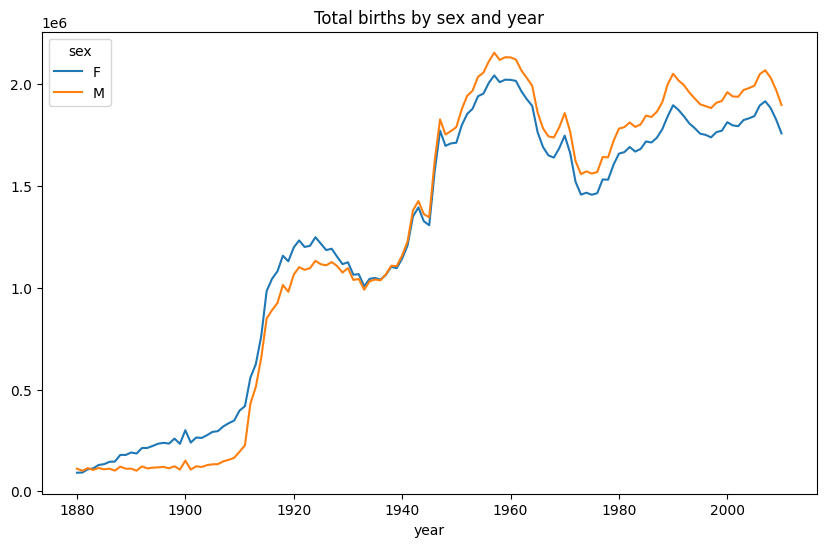

In [ ]:
total_births.plot(title="Total births by sex and year")

In [ ]:
i = 0
for k, v in names.groupby(["year", "sex"]):
    print(k)
    display(v.head())

    i += 1
    if i == 4:  # 0, 1, 2번째 (총 3개 그룹) 확인 후 종료
        break

(np.int64(1880), 'F')


,name,sex,births,year
0,Mary,F,7065,1880
1,Anna,F,2604,1880
2,Emma,F,2003,1880
3,Elizabeth,F,1939,1880
4,Minnie,F,1746,1880


(np.int64(1880), 'M')


,name,sex,births,year
942,John,M,9655,1880
943,William,M,9533,1880
944,James,M,5927,1880
945,Charles,M,5348,1880
946,George,M,5126,1880


(np.int64(1881), 'F')


,name,sex,births,year
2000,Mary,F,6919,1881
2001,Anna,F,2698,1881
2002,Emma,F,2034,1881
2003,Elizabeth,F,1852,1881
2004,Margaret,F,1658,1881


(np.int64(1881), 'M')


,name,sex,births,year
2938,John,M,8769,1881
2939,William,M,8524,1881
2940,James,M,5442,1881
2941,George,M,4664,1881
2942,Charles,M,4637,1881


In [ ]:
def add_prop(group):
    group["prop"] = group["births"] / group["births"].sum()
    return group

names = names.groupby(["year", "sex"],
                      group_keys=False   # 결과 인덱스: 원본인덱스만 유지 -> 깔끔함
                      ).apply(add_prop)

In [ ]:
names

,name,sex,births,year,prop
0,Mary,F,7065,1880,0.077643
1,Anna,F,2604,1880,0.028618
2,Emma,F,2003,1880,0.022013
3,Elizabeth,F,1939,1880,0.021309
4,Minnie,F,1746,1880,0.019188
...,...,...,...,...,...
1690779,Zymaire,M,5,2010,0.000003
1690780,Zyonne,M,5,2010,0.000003
1690781,Zyquarius,M,5,2010,0.000003
1690782,Zyran,M,5,2010,0.000003


In [ ]:
names.groupby(["year", "sex"])["prop"].sum()

year  sex
1880  F      1.0
      M      1.0
1881  F      1.0
      M      1.0
1882  F      1.0
            ... 
2008  M      1.0
2009  F      1.0
      M      1.0
2010  F      1.0
      M      1.0
Name: prop, Length: 262, dtype: float64

In [ ]:
names.groupby(["year", "sex"]).count()

name  births   prop
year sex                      
1880 F      942     942    942
     M     1058    1058   1058
1881 F      938     938    938
     M      997     997    997
1882 F     1028    1028   1028
...         ...     ...    ...
2008 M    14590   14590  14590
2009 F    20123   20123  20123
     M    14479   14479  14479
2010 F    19698   19698  19698
     M    14140   14140  14140

[262 rows x 3 columns]

In [ ]:
def get_top1000(group):
    return group.sort_values("births", ascending=False)[:1000]

grouped = names.groupby(["year", "sex"])
top1000 = grouped.apply(get_top1000)
top1000

name sex  births  year      prop
year sex                                               
1880 F   0             Mary   F    7065  1880  0.077643
         1             Anna   F    2604  1880  0.028618
         2             Emma   F    2003  1880  0.022013
         3        Elizabeth   F    1939  1880  0.021309
         4           Minnie   F    1746  1880  0.019188
...                     ...  ..     ...   ...       ...
2010 M   1677639     Camilo   M     194  2010  0.000102
         1677640     Destin   M     194  2010  0.000102
         1677641     Jaquan   M     194  2010  0.000102
         1677642     Jaydan   M     194  2010  0.000102
         1677643       Crew   M     193  2010  0.000102

[261877 rows x 5 columns]

In [ ]:
# 기존 인덱스를 제거하고 0부터 시작하는 새로운 정수형 인덱스로 다시 설정(리셋)
top1000 = top1000.reset_index(drop=True)

In [ ]:
top1000

,name,sex,births,year,prop
0,Mary,F,7065,1880,0.077643
1,Anna,F,2604,1880,0.028618
2,Emma,F,2003,1880,0.022013
3,Elizabeth,F,1939,1880,0.021309
4,Minnie,F,1746,1880,0.019188
...,...,...,...,...,...
261872,Camilo,M,194,2010,0.000102
261873,Destin,M,194,2010,0.000102
261874,Jaquan,M,194,2010,0.000102
261875,Jaydan,M,194,2010,0.000102


In [ ]:
boys = top1000[top1000["sex"] == "M"]

girls = top1000[top1000["sex"] == "F"]

In [ ]:
total_births = top1000.pivot_table("births", index="year",
                                   columns="name",
                                   aggfunc=sum)

total_births

name,Aaden,Aaliyah,Aarav,Aaron,Aarush,Ab,Abagail,Abb,Abbey,Abbie,...,Zoa,Zoe,Zoey,Zoie,Zola,Zollie,Zona,Zora,Zula,Zuri
year,,,,,,,,,,,,,,,,,,,,,
1880,NaN,NaN,NaN,102.0,NaN,5.0,NaN,NaN,NaN,71.0,...,8.0,23.0,NaN,NaN,7.0,NaN,8.0,28.0,27.0,NaN
1881,NaN,NaN,NaN,94.0,NaN,NaN,NaN,NaN,NaN,81.0,...,NaN,22.0,NaN,NaN,10.0,NaN,9.0,21.0,27.0,NaN
1882,NaN,NaN,NaN,85.0,NaN,5.0,NaN,NaN,NaN,80.0,...,8.0,25.0,NaN,NaN,9.0,NaN,17.0,32.0,21.0,NaN
1883,NaN,NaN,NaN,105.0,NaN,NaN,NaN,NaN,NaN,79.0,...,NaN,23.0,NaN,NaN,10.0,NaN,11.0,35.0,25.0,NaN
1884,NaN,NaN,NaN,97.0,NaN,NaN,NaN,5.0,NaN,98.0,...,13.0,31.0,NaN,NaN,14.0,6.0,8.0,58.0,27.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2006,NaN,3737.0,NaN,8279.0,NaN,NaN,297.0,NaN,404.0,440.0,...,NaN,5145.0,2839.0,530.0,NaN,NaN,NaN,NaN,NaN,NaN
2007,NaN,3941.0,NaN,8914.0,NaN,NaN,313.0,NaN,349.0,468.0,...,NaN,4925.0,3028.0,526.0,NaN,NaN,NaN,NaN,NaN,NaN
2008,955.0,4028.0,219.0,8511.0,NaN,NaN,317.0,NaN,344.0,400.0,...,NaN,4764.0,3438.0,492.0,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
total_births.fillna(0)

name,Aaden,Aaliyah,Aarav,Aaron,Aarush,Ab,Abagail,Abb,Abbey,Abbie,...,Zoa,Zoe,Zoey,Zoie,Zola,Zollie,Zona,Zora,Zula,Zuri
year,,,,,,,,,,,,,,,,,,,,,
1880,0.0,0.0,0.0,102.0,0.0,5.0,0.0,0.0,0.0,71.0,...,8.0,23.0,0.0,0.0,7.0,0.0,8.0,28.0,27.0,0.0
1881,0.0,0.0,0.0,94.0,0.0,0.0,0.0,0.0,0.0,81.0,...,0.0,22.0,0.0,0.0,10.0,0.0,9.0,21.0,27.0,0.0
1882,0.0,0.0,0.0,85.0,0.0,5.0,0.0,0.0,0.0,80.0,...,8.0,25.0,0.0,0.0,9.0,0.0,17.0,32.0,21.0,0.0
1883,0.0,0.0,0.0,105.0,0.0,0.0,0.0,0.0,0.0,79.0,...,0.0,23.0,0.0,0.0,10.0,0.0,11.0,35.0,25.0,0.0
1884,0.0,0.0,0.0,97.0,0.0,0.0,0.0,5.0,0.0,98.0,...,13.0,31.0,0.0,0.0,14.0,6.0,8.0,58.0,27.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2006,0.0,3737.0,0.0,8279.0,0.0,0.0,297.0,0.0,404.0,440.0,...,0.0,5145.0,2839.0,530.0,0.0,0.0,0.0,0.0,0.0,0.0
2007,0.0,3941.0,0.0,8914.0,0.0,0.0,313.0,0.0,349.0,468.0,...,0.0,4925.0,3028.0,526.0,0.0,0.0,0.0,0.0,0.0,0.0
2008,955.0,4028.0,219.0,8511.0,0.0,0.0,317.0,0.0,344.0,400.0,...,0.0,4764.0,3438.0,492.0,0.0,0.0,0.0,0.0,0.0,0.0


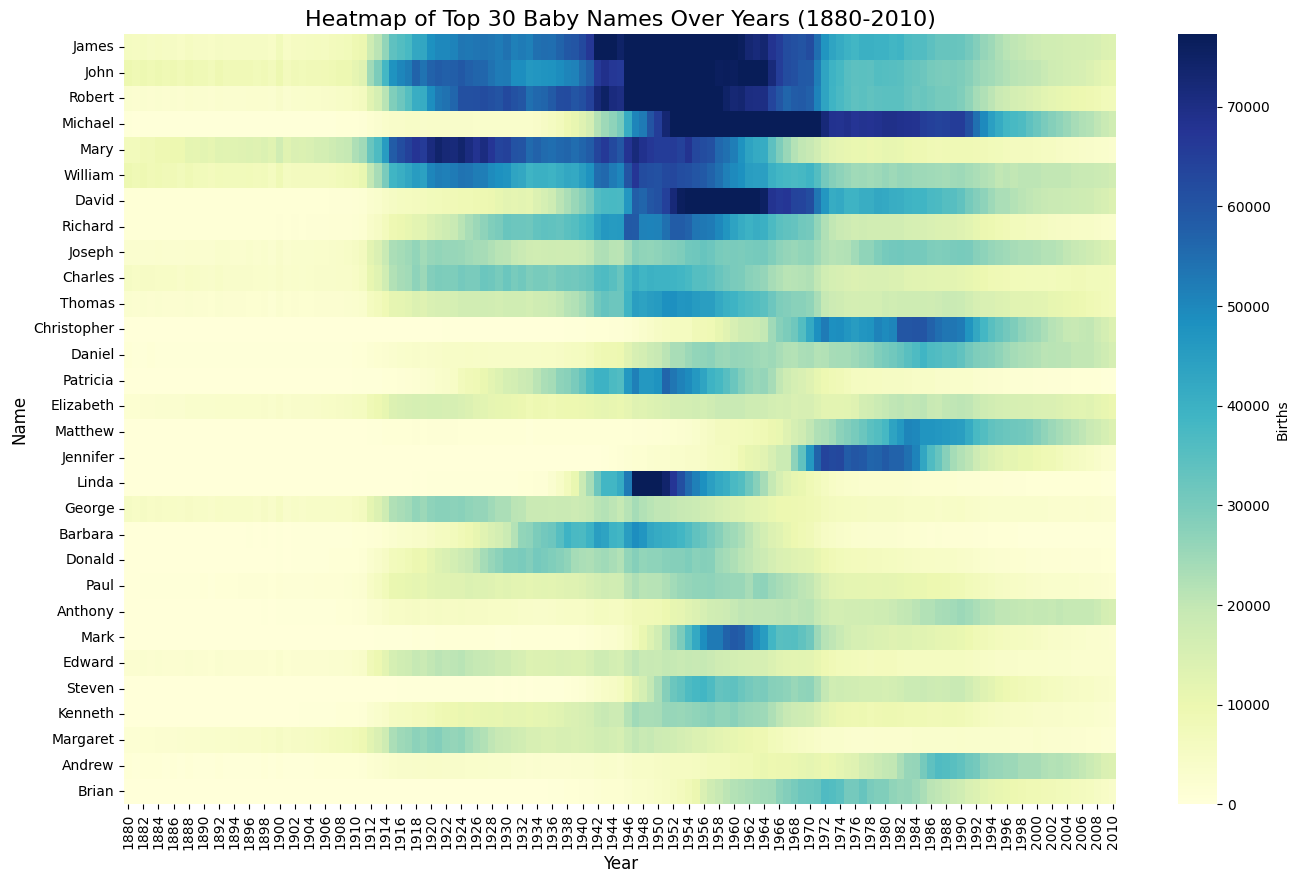

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 누적 출생수가 가장 많은 상위 30개 이름 선택
top_names = total_births.sum().sort_values(ascending=False).head(30).index

# 결측치를 0으로 채우고 상위 30개 이름만 필터링
heatmap_data = total_births[top_names].fillna(0).T

# 히트맵 그리기
plt.figure(figsize=(16, 10))
sns.heatmap(heatmap_data, cmap="YlGnBu", robust=True, cbar_kws={'label': 'Births'})
plt.title("Heatmap of Top 30 Baby Names Over Years (1880-2010)", fontsize=16)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Name", fontsize=12)
plt.show()

In [ ]:
total_births.info()

<class 'pandas.core.frame.DataFrame'>
Index: 131 entries, 1880 to 2010
Columns: 6862 entries, Aaden to Zuri
dtypes: float64(6862)
memory usage: 6.9 MB


In [ ]:
subset = total_births[["John", "Harry", "Mary", "Marilyn"]]
subset

name,John,Harry,Mary,Marilyn
year,,,,
1880,9701.0,2158.0,7092.0,NaN
1881,8795.0,2002.0,6948.0,NaN
1882,9597.0,2246.0,8179.0,NaN
1883,8934.0,2116.0,8044.0,NaN
1884,9427.0,2338.0,9253.0,NaN
...,...,...,...,...
2006,15140.0,414.0,4073.0,596.0
2007,14405.0,443.0,3665.0,597.0
2008,13273.0,379.0,3478.0,543.0


array([<Axes: xlabel='year'>, <Axes: xlabel='year'>,
       <Axes: xlabel='year'>, <Axes: xlabel='year'>], dtype=object)

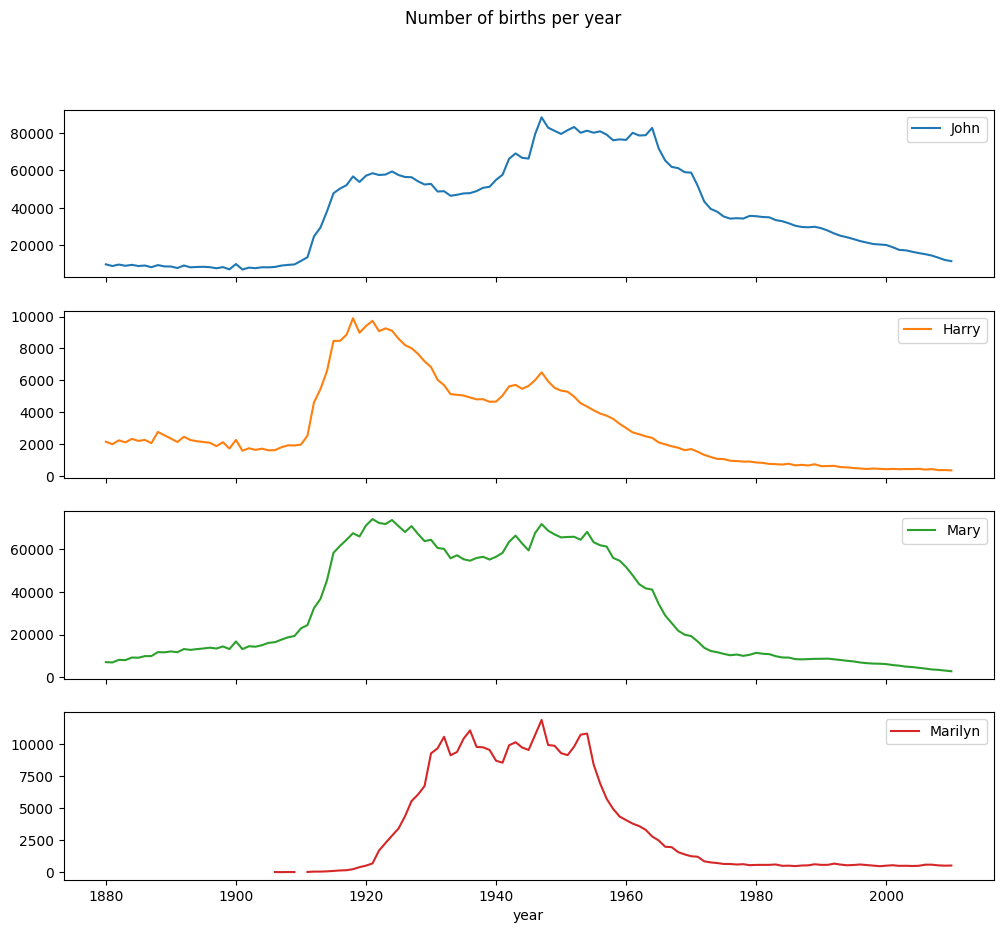

In [ ]:
subset.plot(subplots=True, figsize=(12, 10),
            title="Number of births per year")

In [ ]:
top1000

,name,sex,births,year,prop
0,Mary,F,7065,1880,0.077643
1,Anna,F,2604,1880,0.028618
2,Emma,F,2003,1880,0.022013
3,Elizabeth,F,1939,1880,0.021309
4,Minnie,F,1746,1880,0.019188
...,...,...,...,...,...
261872,Camilo,M,194,2010,0.000102
261873,Destin,M,194,2010,0.000102
261874,Jaquan,M,194,2010,0.000102
261875,Jaydan,M,194,2010,0.000102


In [ ]:
plt.figure()

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [ ]:
# @title 상위 천 명의 성을 가진 baby의 성별로 전체 baby에 대한 비중(Percentage)
table = top1000.pivot_table("prop", index="year",
                            columns="sex", aggfunc=sum)

table

sex,F,M
year,,
1880,1.000000,0.997375
1881,1.000000,1.000000
1882,0.998702,0.995646
1883,0.997596,0.998566
1884,0.993156,0.994539
...,...,...
2006,0.753153,0.860368
2007,0.745959,0.855159
2008,0.740933,0.850003


<Axes: title={'center': 'Sum of table1000.prop by year and sex'}, xlabel='year'>

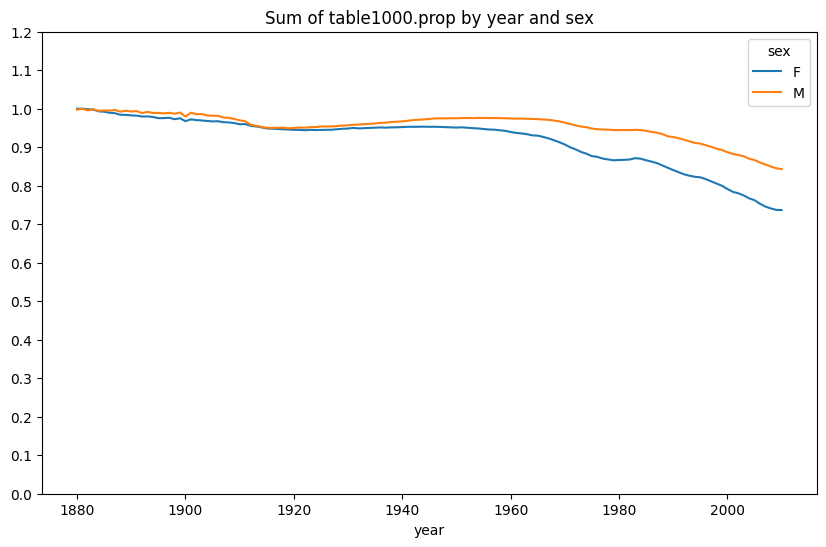

In [ ]:
table.plot(title="Sum of table1000.prop by year and sex",
           yticks=np.linspace(0, 1.2, 13))

In [ ]:
df = boys[boys["year"] == 2010]
df

,name,sex,births,year,prop
260877,Jacob,M,21875,2010,0.011523
260878,Ethan,M,17866,2010,0.009411
260879,Michael,M,17133,2010,0.009025
260880,Jayden,M,17030,2010,0.008971
260881,William,M,16870,2010,0.008887
...,...,...,...,...,...
261872,Camilo,M,194,2010,0.000102
261873,Destin,M,194,2010,0.000102
261874,Jaquan,M,194,2010,0.000102
261875,Jaydan,M,194,2010,0.000102


In [ ]:
# @title table 데이터프레임의 2010년도 남자의 상위 1000명의 비중과 동일
prop_cumsum = df["prop"].sort_values(ascending=False).cumsum()
prop_cumsum

,prop
260877,0.011523
260878,0.020934
260879,0.029959
260880,0.038930
260881,0.047817
...,...
261872,0.842748
261873,0.842850
261874,0.842953
261875,0.843055


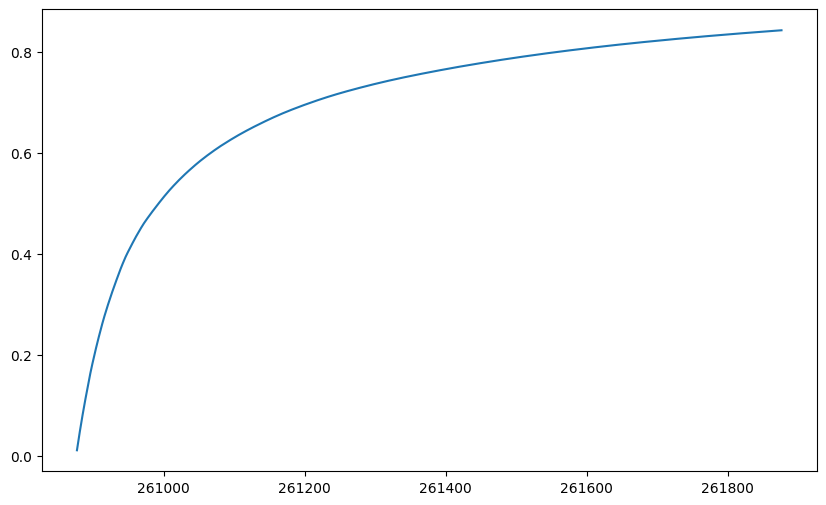

In [ ]:
plt.plot(prop_cumsum)

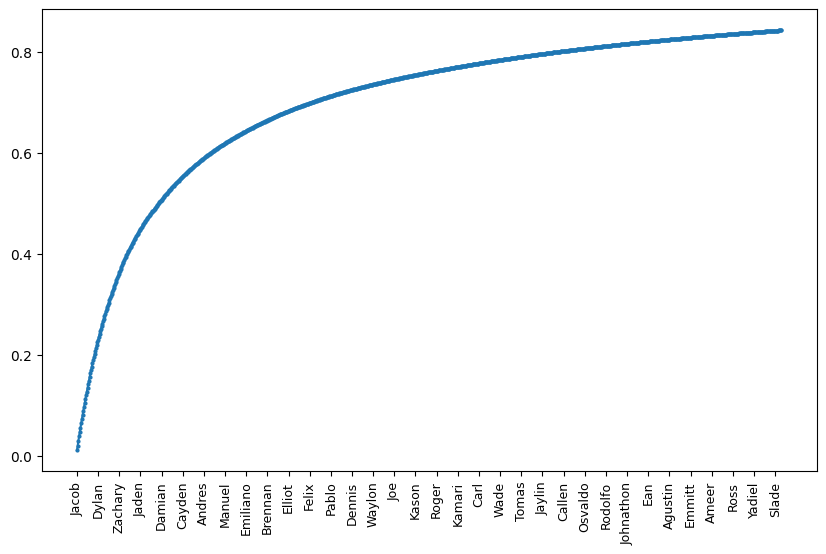

In [ ]:
names = df.loc[prop_cumsum.index, 'name'].values

plt.plot(prop_cumsum.values, marker='o', markersize=2, label='Cumulative Proportion')
plt.xticks(range(0, len(names), 30), names[::30], rotation=90, fontsize=9);

In [ ]:
prop_cumsum.searchsorted(0.5)

np.int64(116)

In [ ]:
df = boys[boys.year == 1900]
df

,name,sex,births,year,prop
40877,John,M,9834,1900,0.065319
40878,William,M,8580,1900,0.056990
40879,James,M,7246,1900,0.048129
40880,George,M,5405,1900,0.035901
40881,Charles,M,4102,1900,0.027246
...,...,...,...,...,...
41872,Gerhard,M,8,1900,0.000053
41873,Gertrude,M,8,1900,0.000053
41874,Heber,M,8,1900,0.000053
41875,Hillard,M,8,1900,0.000053


In [ ]:
# @title 1900년 남자 아기 중에서 가장 인기 있는 상위 이름 몇 개가 전체 신생아의 절반(50%, 0.5)을 차지하는지 계산
in1900 = df.sort_values("prop", ascending=False).prop.cumsum()
in1900

,prop
40877,0.065319
40878,0.122308
40879,0.170437
40880,0.206338
40881,0.233584
...,...
41872,0.979489
41873,0.979542
41874,0.979595
41875,0.979648


In [ ]:
in1900.searchsorted(0.5)

np.int64(24)

In [ ]:
in1900.searchsorted(0.5) + 1

np.int64(25)

**이름 다양성의 증가 (개성 중시 문화)**

- 1880년대 - 1900년대에는 단 10 - 20여 개의 상위 이름만으로 전체 신생아의 절반을 차지

- 현대로 올수록: 부모들이 흔한 이름 대신 다양하고 독특한 이름을 선호하게 되면서, 전체 50%를 채우는 데 필요한 이름의 개수(diversity 값)가 크게 증가(수백 개 단위)하는 현상을 확인

In [ ]:
def get_quantile_count(group, q=0.5):
    group = group.sort_values("prop", ascending=False)
    return group.prop.cumsum().searchsorted(q) + 1

diversity = top1000.groupby(["year", "sex"]).apply(get_quantile_count)
diversity

year  sex
1880  F       38
      M       14
1881  F       38
      M       14
1882  F       38
            ... 
2008  M      109
2009  F      241
      M      114
2010  F      246
      M      117
Length: 262, dtype: int64

In [ ]:
diversity = diversity.unstack()
diversity

sex,F,M
year,,
1880,38,14
1881,38,14
1882,38,15
1883,39,15
1884,39,16
...,...,...
2006,209,99
2007,223,103
2008,234,109


In [ ]:
fig = plt.figure()

<Figure size 1000x600 with 0 Axes>

<Axes: title={'center': 'Number of popular names in top 50%'}, xlabel='year'>

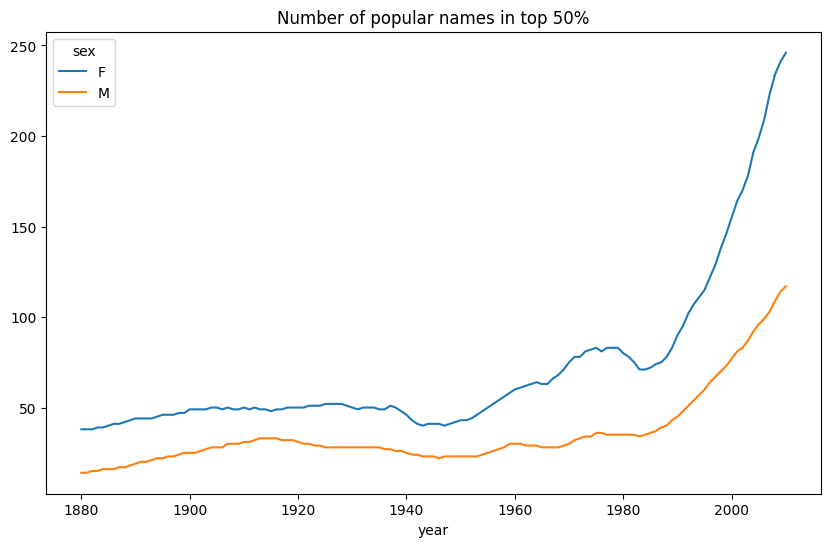

In [ ]:
diversity.head()
diversity.plot(title="Number of popular names in top 50%")

In [ ]:
def get_last_letter(x):
    return x[-1]

last_letters = pd.Series(names).map(get_last_letter)
last_letters

,0
0,b
1,n
2,l
3,n
4,m
...,...
995,o
996,n
997,n
998,n


In [ ]:
last_letters.name = "last_letter"
last_letters

,last_letter
0,b
1,n
2,l
3,n
4,m
...,...
995,o
996,n
997,n
998,n


In [ ]:
table = top1000.pivot_table("births", index=last_letters,
                          columns=["sex", "year"], aggfunc=sum)
table

sex,F,M
year,1880,1880
last_letter,,
a,1397.0,NaN
b,7888.0,NaN
c,1216.0,NaN
d,1672.0,8590.0
e,4224.0,9857.0
...,...,...
v,15.0,1024.0
w,2161.0,305.0


In [ ]:
table.fillna(0)

sex,F,M
year,1880,1880
last_letter,,
a,1397.0,0.0
b,7888.0,0.0
c,1216.0,0.0
d,1672.0,8590.0
e,4224.0,9857.0
...,...,...
v,15.0,1024.0
w,2161.0,305.0


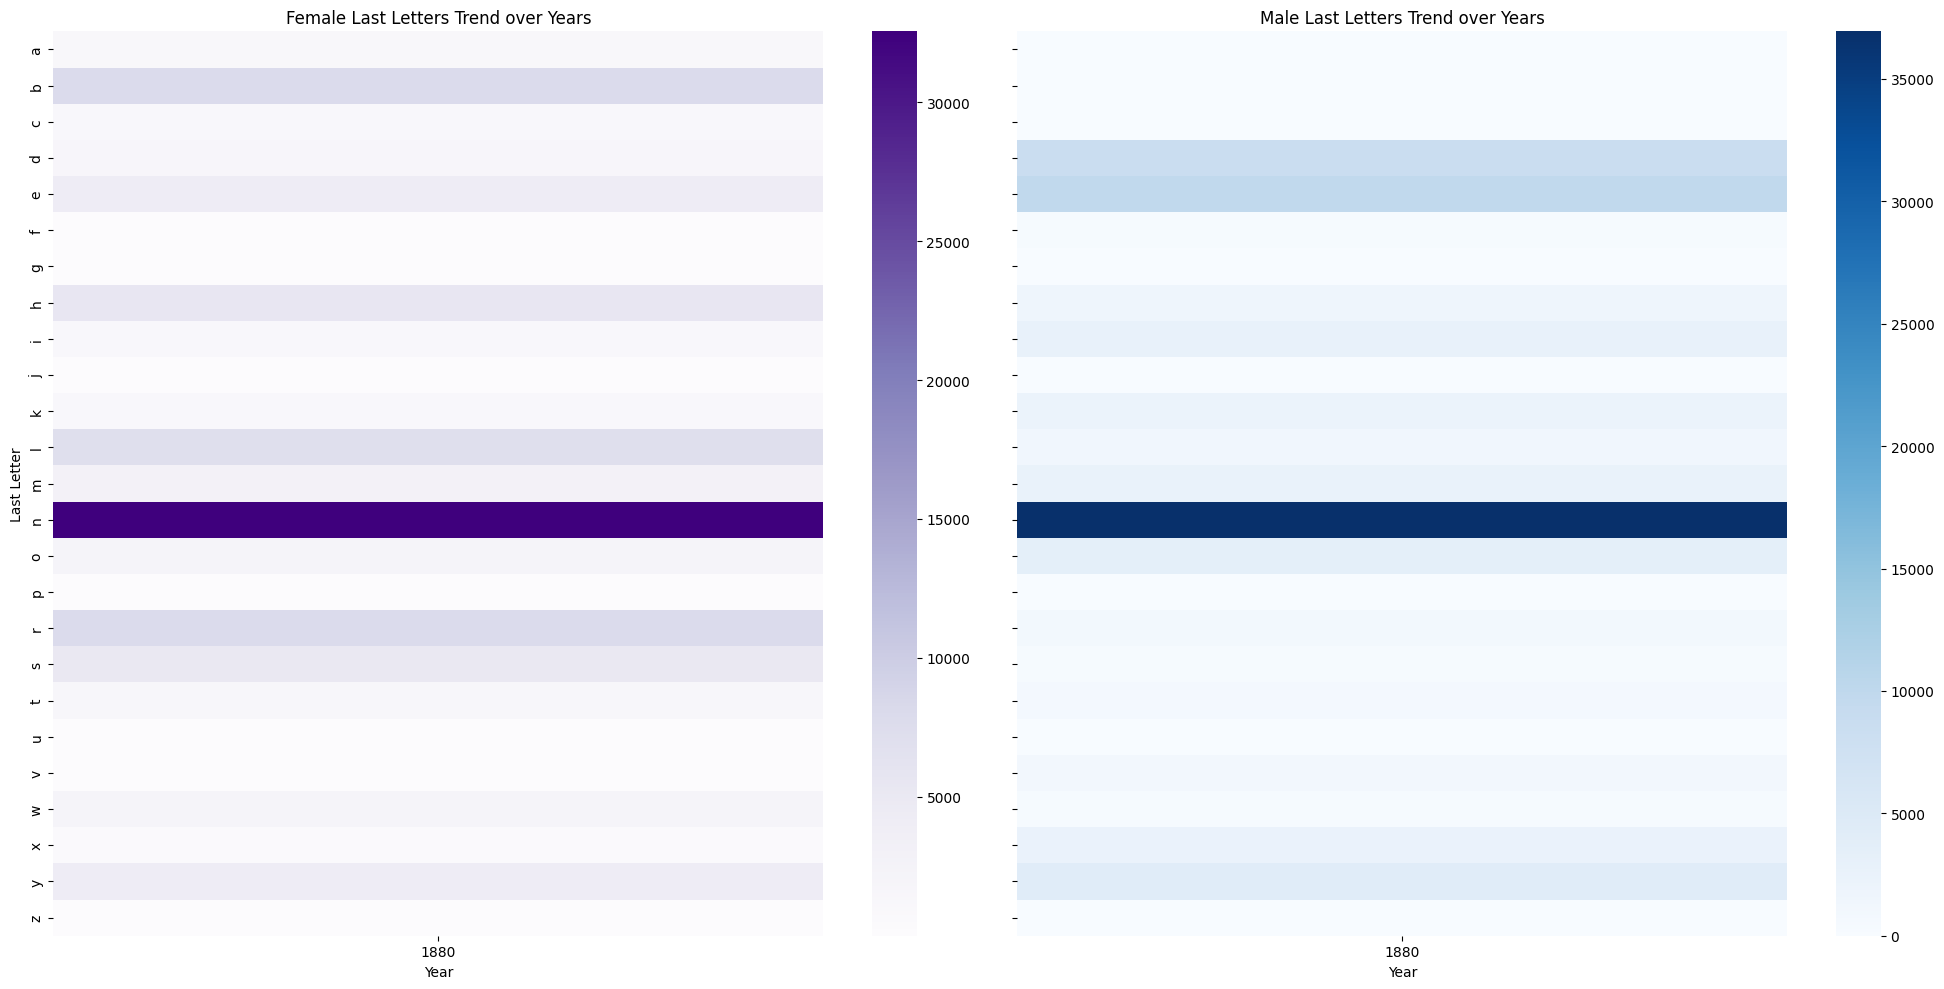

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# 결측치를 0으로 채운 테이블 준비
table_filled = table.fillna(0)

# 성별('M' / 'F')에 맞춰 시각화하거나 전체를 하나의 히트맵으로 표현
# 여기서는 시각적 이해를 돕기 위해 여성(F)과 남성(M) 각각에 대한 마지막 글자 빈도 히트맵을 나누어 그립니다.
fig, axes = plt.subplots(1, 2, figsize=(20, 10), sharey=True)

sns.heatmap(table_filled["F"], cmap="Purples", ax=axes[0])
axes[0].set_title("Female Last Letters Trend over Years")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Last Letter")

sns.heatmap(table_filled["M"], cmap="Blues", ax=axes[1])
axes[1].set_title("Male Last Letters Trend over Years")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [ ]:
table.head()

sex,F,M
year,1880,1880
last_letter,,
a,1397.0,NaN
b,7888.0,NaN
c,1216.0,NaN
d,1672.0,8590.0
e,4224.0,9857.0


In [ ]:
subtable = table.reindex(columns=[1910, 1960, 2010], level="year")
subtable

last_letter
a
b
c
d
e
...
v
w
x
y


In [ ]:
subtable.sum(0) # subtable.sum(1)

,,0
sex,year,


In [ ]:
letter_prop = subtable / subtable.sum()
letter_prop

last_letter
a
b
c
d
e
...
v
w
x
y


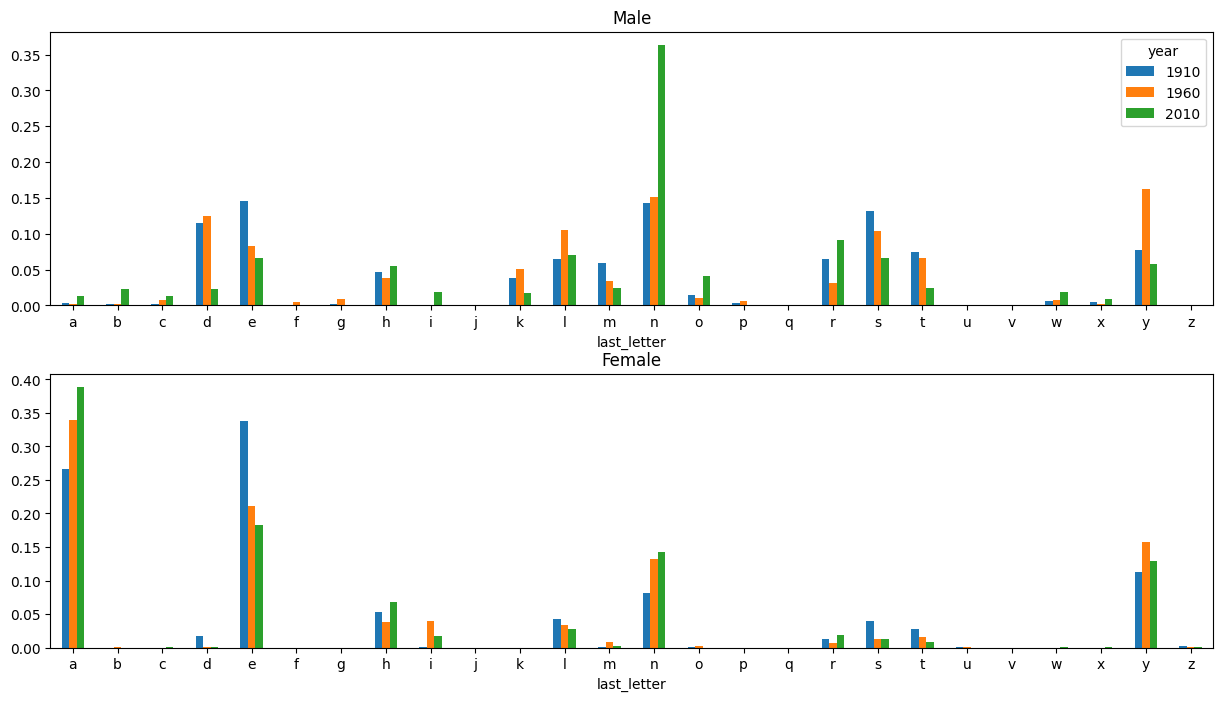

In [ ]:
import matplotlib.pyplot as plt

# 1. top1000 전체 행에 대한 정확한 last_letters 생성
get_last_letter = lambda x: x[-1]
last_letters = top1000["name"].map(get_last_letter)
last_letters.name = "last_letter"

# 2. 올바른 피벗 테이블 생성
table = top1000.pivot_table("births", index=last_letters,
                            columns=["sex", "year"], aggfunc=sum)

# 3. 1910, 1960, 2010년도 서브셋 재추출 및 비율 계산
subtable = table.reindex(columns=[1910, 1960, 2010], level="year")
letter_prop = subtable / subtable.sum()

# 4. 정상 시각화
fig, axes = plt.subplots(2, 1, figsize=(15, 8))
plt.subplots_adjust(hspace=0.25)
letter_prop["M"].plot(kind="bar", rot=0, ax=axes[0], title="Male")
letter_prop["F"].plot(kind="bar", rot=0, ax=axes[1], title="Female", legend=False)
plt.show()

In [ ]:
table.head()

In [ ]:
letter_prop = table / table.sum()
letter_prop

In [ ]:
# @title 마지막 이름의 문자가 ["d", "n", "y"]인 남자만
letter_prop.loc[["d", "n", "y"], "M"]

In [ ]:
letter_prop.loc[["d", "n", "y"], "M"].T

In [ ]:
dny_ts = letter_prop.loc[["d", "n", "y"], "M"].T
dny_ts.head()

In [ ]:
plt.close("all")

In [ ]:
fig = plt.figure()

In [ ]:
dny_ts.plot()

In [ ]:
all_names = pd.Series(top1000["name"].unique())
all_names

In [ ]:
lesley_like = all_names[all_names.str.contains("Lesl")]
lesley_like

In [ ]:
filtered = top1000[top1000["name"].isin(lesley_like)]
filtered

In [ ]:
filtered.groupby("name")["births"].sum()

In [ ]:
table = filtered.pivot_table("births", index="year",
                             columns="sex", aggfunc="sum")
table

In [ ]:
table

In [ ]:
table.sum(1).head(3)

In [ ]:
table.sum(axis="columns").head(3)

In [ ]:
# @title "연도별 총 출생 수"를 구하고, 이를 기준으로 남녀 비율(정규화, Normalization)을 계산
table = table.div(table.sum(axis="columns"), axis="index")
table

In [ ]:
fig = plt.figure()

In [ ]:
# @title top1000 데이터에서 "Lesl"라는 이름이 포함된 남녀 인구수 성별 비율
table.plot(style={"M": "k-", "F": "k--"})